# Piotrowski et al. (2023): simultaneous ground-state cooling of two mechanical modes

J. Piotrowski, D. Windey, J. Vijayan, C. Gonzalez-Ballestero, A. de los Ríos Sommer, N. Meyer,
R. Quidant, O. Romero-Isart, R. Reimann and L. Novotny,
*Simultaneous ground-state cooling of two mechanical modes of a levitated nanoparticle*,
Nat. Phys. **19**, 1009 (2023), [doi:10.1038/s41567-023-01956-1](https://doi.org/10.1038/s41567-023-01956-1).

A 143 nm silica sphere in a 1550 nm tweezer, polarised at $\theta = \pi/4$ to the cavity axis,
couples both transverse modes to one cavity mode by coherent scattering. With the cavity detuned
to $(\Omega_x + \Omega_y)/2$ both modes reach the ground state, $n_x = 0.83$ and $n_y = 0.81$.
This is levisim's one-particle, two-axis system (`Cartesian_axes_per_trap=2`) including the
bright/dark-mode physics of near-degenerate modes. The notebook compares

1. couplings and heating rates computed from the stated parameters with the paper's Methods,
2. $n_x$, $n_y$ against detuning (Fig. 2b),
3. $n_x$, $n_y$ against the polarisation angle (Fig. 3e),
4. the systematic error of sideband thermometry against mode splitting and coupling (Fig. 4d,e),
   which is a pure-theory figure that levisim can reproduce in full.

Runtime: about a minute (the sideband-thermometry map takes about 20 s).

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| wavelength, power at the focus, NA | 1550 nm, 1.20 W, 0.75 | Methods, "Experimental setup" |
| tweezer waists $w_x$ (polarisation), $w_y$ | 1.023 μm, 0.856 μm | Methods, "Calculated heating rates" |
| particle diameter, mass, index | 143 nm, 3.4 fg, $n_r$ = 1.439 | Methods |
| frequencies $(\Omega_x, \Omega_y, \Omega_z)/2\pi$ | (224, 268, 80) kHz | main text |
| cavity linewidth, finesse, waist, length | 330 kHz, 70 000, 48 μm, 6.4 mm | main text and Methods |
| polarisation angle | $\theta = 0.25\pi$ (Fig. 2), 0.25-0.5π (Fig. 3) | main text |
| pressure | 5 × 10⁻⁹ mbar | Methods |
| fitted couplings and heating rates | $g_x/2\pi$ = 14.1 ± 2.7 kHz, $g_y/2\pi$ = 15.4 ± 1.9 kHz, $\Gamma_x = \Gamma_y = 2\pi \times (1.0 \pm 0.4)$ kHz | main text |

**Axes and signs.** The paper's $x$ is the polarisation axis; levisim's tweezer is polarised along
its $y$ axis. So the paper's $x$ mode is levisim's `'y1'` and the paper's $y$ mode is levisim's
`'x1'`; tables and plots below use the paper's labels. Both define $\theta$ as the angle between
the polarisation and the cavity axis. The paper's $\Delta = \omega_c - \omega_0 > 0$ is red
detuning, the negative of levisim's.

**Modelling choices.** Recoil heating is added with `paper_tools.add_heating` (levisim's quantum
linear theory only has the gas bath). The particle sits exactly at the node, where $z$ decouples,
so the $x$-$y$ model is complete, as in the paper's Methods.

In [ ]:
import sys
import time
import itertools
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.signal import find_peaks
from scipy.optimize import minimize_scalar

from levisim.core.constants import π, ħ, kB, c
from levisim.core.units import kHz, Hz, nm, μm, mm, mbar, fg
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.tweezer import Tweezer
from levisim.physics.bead import Bead
from levisim.physics.trap import Trap
from levisim.multiphysics.enums import QuantumLinearTheoryMethod

from paper_tools import (
    PhysicalMultiTrap, toy_multitrap, recoil_heating_rates, add_heating, gas_heating_rate,
    occupations, heterodyne, load_digitised, quiet,
)

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
T_START = time.time()

## Couplings and heating rates from the stated parameters

In [ ]:
R, M = 143/2*nm, 3.4*fg
ρ = M / (4/3 * π * R**3)
κ_P = 330*kHz
Ω_PAPER = {'x': 224*kHz, 'y': 268*kHz, 'z': 80*kHz}                 # paper axes
Ω_LEVISIM = {'x': Ω_PAPER['y'], 'y': Ω_PAPER['x'], 'z': Ω_PAPER['z']}  # levisim axes
PAPER_TO_LEVISIM = {'x': 'y1', 'y': 'x1'}


def piotrowski_tweezer(θ=0.25*π):
    # levisim wx0 is perpendicular to the polarisation (paper y), wy0 along it (paper x)
    return Tweezer(Power=1.20, λ=1550*nm, wx0=0.856*μm, wy0=1.023*μm, θ=θ)


def piotrowski_multitrap(Δ_paper, θ=0.25*π, P=5e-9*mbar, axes=2):
    tweezer = piotrowski_tweezer(θ)
    bead = Bead(r=R, ρ=ρ, εr=1.439**2, Φ=π/2)
    mtrap = PhysicalMultiTrap(
        [tweezer], [bead], trap_kwargs=[dict(override_Ω_dict=Ω_LEVISIM)],
        Cartesian_axes_per_trap=axes, gas_kwargs=dict(P=P, T=300.0),
        cavity_kwargs=dict(L=6.4*mm, w=48*μm, Finesse=70_000, κ=κ_P, Δ=-Δ_paper, ωtw=tweezer.ω),
    )
    rates = recoil_heating_rates(mtrap.traps[0])
    add_heating(mtrap, {label: rates[label[0]] for label in mtrap.labels})
    return mtrap


mtrap = piotrowski_multitrap(232*kHz)
trap = mtrap.traps[0]
paraxial = Trap(tweezer=trap.tweezer, bead=trap.bead)
recoil = recoil_heating_rates(trap)
Γ_gas = mtrap.dimensions['x1'].Γ
γ_paper = 4812 * 5e-9    # Methods: γ = 4,812 Hz × p_gas,mbar
rows = [
    ('density from 3.4 fg and 143 nm [kg/m³]', ρ, '-'),
    ('Ωx/2π (polarisation), paraxial [kHz]', paraxial.Ωy/kHz, '224 (measured)'),
    ('Ωy/2π, paraxial [kHz]', paraxial.Ωx/kHz, '268 (measured)'),
    ('Ωz/2π, paraxial [kHz]', paraxial.Ωz/kHz, '80 (measured)'),
    ('κ/2π from F and L [kHz]', π*c/(70_000*6.4*mm)/kHz, '330 ± 9 (measured)'),
    ('G0/2π = 2ω_d/2π [GHz]', 2*trap.ωd/(1e9*Hz), '-'),
    ('g_x/2π, Eq. (1) [kHz]', abs(mtrap.dimensions['y1'].g)/kHz, '14.1 ± 2.7 (fitted)'),
    ('g_y/2π, Eq. (1) [kHz]', abs(mtrap.dimensions['x1'].g)/kHz, '15.4 ± 1.9 (fitted)'),
    ('Γ_x^(r)/2π recoil [kHz]', recoil['y']/kHz, '0.825'),
    ('Γ_y^(r)/2π recoil [kHz]', recoil['x']/kHz, '1.379'),
    ('gas damping γ [1/s] (levisim Epstein)', Γ_gas, f'{γ_paper:.3e} (4,812 Hz × p)'),
    ('Γ_x^(g)/2π = γ kBT/ħΩx [kHz]', gas_heating_rate(mtrap, 'y1')/kHz, '0.053'),
    ('Γ_y^(g)/2π = γ kBT/ħΩy [kHz]', gas_heating_rate(mtrap, 'x1')/kHz, '0.045'),
    ('  same, with the paper\'s γ [kHz]', γ_paper*kB*300/(ħ*Ω_PAPER['x'])/kHz, '0.053'),
]
print(f'{"quantity (paper axes)":42s} {"levisim":>10s}   paper')
for name, value, paper in rows:
    print(f'{name:42s} {value:10.4g}   {paper}')
print(f'\nEq. (1) / fitted: g_x {abs(mtrap.dimensions["y1"].g)/(14.1*kHz):.2f}, g_y {abs(mtrap.dimensions["x1"].g)/(15.4*kHz):.2f}')

quantity (paper axes)                         levisim   paper
density from 3.4 fg and 143 nm [kg/m³]           2221   -
Ωx/2π (polarisation), paraxial [kHz]            223.7   224 (measured)
Ωy/2π, paraxial [kHz]                           267.4   268 (measured)
Ωz/2π, paraxial [kHz]                           91.18   80 (measured)
κ/2π from F and L [kHz]                         334.6   330 ± 9 (measured)
G0/2π = 2ω_d/2π [GHz]                           10.35   -
g_x/2π, Eq. (1) [kHz]                           34.81   14.1 ± 2.7 (fitted)
g_y/2π, Eq. (1) [kHz]                           31.82   15.4 ± 1.9 (fitted)
Γ_x^(r)/2π recoil [kHz]                        0.8203   0.825
Γ_y^(r)/2π recoil [kHz]                         1.371   1.379
gas damping γ [1/s] (levisim Epstein)       2.383e-05   2.406e-05 (4,812 Hz × p)
Γ_x^(g)/2π = γ kBT/ħΩx [kHz]                   0.1058   0.053
Γ_y^(g)/2π = γ kBT/ħΩy [kHz]                  0.08844   0.045
  same, with the paper's γ [kHz]               0.1069 

Three findings from this table:

- The paraxial frequencies from the stated power and waists reproduce the measured $x$ and $y$
  frequencies, so the waists were presumably inferred from them in the same model.
- levisim's recoil rates reproduce the Methods values, and its gas damping agrees with the
  Methods' $\gamma$. The Methods' gas heating rates (0.053 and 0.045 kHz) are, however, half of
  their own Eq. (3) evaluated with their own $\gamma$. This does not matter for the results,
  because recoil dominates by more than an order of magnitude.
- The coupling rates from Eq. (1) with the stated parameters - which is exactly levisim's coupling -
  are about twice the fitted ones. The paper does not compare the two, and nothing in levisim
  enters beyond Eq. (1). Some reduction of the effective scattering into the cavity mode in the
  experiment is the likely cause (for example tweezer power at the focus, or the overlap of the
  focus with the cavity mode). Below we use the **fitted** couplings, as the paper does
  for its simulations, and show the first-principles prediction for comparison.

Eq. (1) also needs the polarisation dependence of $G_0$. The Methods write it as
$\propto \cos\theta$ through $\mathbf e_x \cdot \mathbf e_\alpha$. With $\theta$ measured from
the cavity axis, as in this paper, the dipole radiates into the cavity mode
$\propto \sin\theta$; $\cos\Theta$ is the form in Gonzalez-Ballestero et al., PRA 100, 013805
(2019), whose $\Theta$ is measured from the perpendicular. levisim uses $\sin\theta$. The
$\theta$-dependence below (Fig. 3e) tests this.

## Occupations against detuning (Fig. 2b)

levisim model with the fitted $g_j$ and $\Gamma_j$ (toy-parameter `MultiTrap`, with the full
$x$-$y$-cavity linear dynamics); the band spans all 16 corners of $g_j \pm \sigma$, $\Gamma_j \pm \sigma$.
The measured points and the paper's theory bands come from the vector graphics of the figure
(`data/piotrowski2023_fig2b_fig3e.json`).

In [ ]:
def fitted_rates_multitrap(Δ_paper, g_x=14.1*kHz, g_y=15.4*kHz, Γ_x=1.0*kHz, Γ_y=1.0*kHz,
                           Ω_x=Ω_PAPER['x'], Ω_y=Ω_PAPER['y']):
    """paper axes in, levisim labels inside: paper x = 'y1', paper y = 'x1'"""
    return toy_multitrap({'y1': Ω_x, 'x1': Ω_y}, {'y1': -g_x, 'x1': -g_y}, {'y1': Γ_x, 'x1': Γ_y},
                         Δ=-Δ_paper, κ=κ_P, m=M, Γ=Γ_gas)


def n_paper_axes(mtrap_):
    n = occupations(mtrap_)
    return np.array([n['y1'], n['x1']])


data = load_digitised('piotrowski2023_fig2b_fig3e.json')
Δs = np.arange(200, 1001, 10.0)
n_central = np.array([n_paper_axes(fitted_rates_multitrap(d*kHz)) for d in Δs])
n_first_principles = np.array([n_paper_axes(piotrowski_multitrap(d*kHz)) for d in Δs])
corners = list(itertools.product([14.1 - 2.7, 14.1 + 2.7], [15.4 - 1.9, 15.4 + 1.9], [0.6, 1.4], [0.6, 1.4]))
n_corners = np.array([[n_paper_axes(fitted_rates_multitrap(d*kHz, gx*kHz, gy*kHz, Gx*kHz, Gy*kHz)) for d in Δs]
                      for gx, gy, Gx, Gy in corners])
band_lo, band_hi = n_corners.min(axis=0), n_corners.max(axis=0)

pb = data['fig2b']
pΔ = np.array(pb['theory_band_x']['Δ_kHz'])
print(f'{"Δ/2π":>6s} | {"n_x meas":>8s} {"levisim":>8s} {"levisim band":>14s} {"paper band":>13s} | {"n_y meas":>8s} {"levisim":>8s} {"levisim band":>14s} {"paper band":>13s}')
for p in pb['points']:
    d, k = p['Δ_kHz']*kHz, np.argmin(abs(pΔ - p['Δ_kHz']))
    n_c = n_paper_axes(fitted_rates_multitrap(d))
    n_k = np.array([n_paper_axes(fitted_rates_multitrap(d, gx*kHz, gy*kHz, Gx*kHz, Gy*kHz)) for gx, gy, Gx, Gy in corners])
    lo, hi = n_k.min(axis=0), n_k.max(axis=0)
    bx = f"{pb['theory_band_x']['lower'][k]:.2f}-{pb['theory_band_x']['upper'][k]:.2f}"
    by = f"{pb['theory_band_y']['lower'][k]:.2f}-{pb['theory_band_y']['upper'][k]:.2f}"
    print(f"{p['Δ_kHz']:6.1f} | {p['n_x']:8.3f} {n_c[0]:8.3f} {f'{lo[0]:.2f}-{hi[0]:.2f}':>14s} {bx:>13s} |"
          f" {p['n_y']:8.3f} {n_c[1]:8.3f} {f'{lo[1]:.2f}-{hi[1]:.2f}':>14s} {by:>13s}")
n_fp = n_paper_axes(piotrowski_multitrap(232.5*kHz))
print(f'\nfirst principles (Eq. (1) couplings) at 232.5 kHz: n_x = {n_fp[0]:.3f}, n_y = {n_fp[1]:.3f}')

  Δ/2π | n_x meas  levisim   levisim band    paper band | n_y meas  levisim   levisim band    paper band
 232.5 |    0.827    0.596      0.33-1.13     0.34-0.88 |    0.814    0.528      0.31-0.87     0.34-0.74
 361.6 |    1.588    0.911      0.47-1.80     0.47-1.37 |    1.633    0.619      0.34-1.06     0.37-0.87
 511.6 |    4.356    2.231      1.07-4.54     1.07-3.41 |    3.183    1.488      0.79-2.61     0.84-2.11
 661.6 |   11.394    4.777      2.22-9.88     2.22-7.40 |    6.882    3.267      1.68-5.80     1.81-4.68
 961.5 |   29.436   14.791     6.60-31.09    6.60-23.21 |   13.041   10.369     5.16-18.62    5.60-15.01

first principles (Eq. (1) couplings) at 232.5 kHz: n_x = 0.219, n_y = 0.277


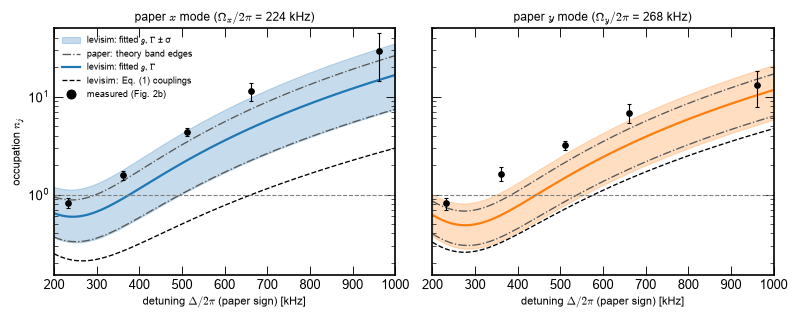

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for i, (ax, mode, colour) in enumerate(zip(axes, 'xy', ('C0', 'C1'))):
    band = pb[f'theory_band_{mode}']
    ax.fill_between(Δs, band_lo[:, i], band_hi[:, i], color=colour, alpha=0.25, label='levisim: fitted $g$, $\\Gamma$ ± σ')
    ax.plot(band['Δ_kHz'], band['lower'], color='0.35', lw=1.2, ls='-.', label='paper: theory band edges')
    ax.plot(band['Δ_kHz'], band['upper'], color='0.35', lw=1.2, ls='-.')
    ax.plot(Δs, n_central[:, i], color=colour, lw=2, label='levisim: fitted $g$, $\\Gamma$')
    ax.plot(Δs, n_first_principles[:, i], 'k--', lw=1.2, label='levisim: Eq. (1) couplings')
    for p in pb['points']:
        ax.errorbar(p['Δ_kHz'], p[f'n_{mode}'], yerr=[[p[f'n_{mode}'] - p[f'n_{mode}_lo']], [p[f'n_{mode}_hi'] - p[f'n_{mode}']]],
                    fmt='o', color='k', ms=5, capsize=2, zorder=5)
    ax.errorbar([], [], fmt='o', color='k', label='measured (Fig. 2b)')
    ax.axhline(1, color='grey', ls='--', lw=1)
    ax.set_yscale('log')
    ax.set_xlim(Δs[0], Δs[-1])
    ax.set_ylim(0.15, 50)
    ax.set_xlabel(r'detuning $\Delta/2\pi$ (paper sign) [kHz]')
    ax.set_title(f'paper ${mode}$ mode ($\\Omega_{mode}/2\\pi$ = {Ω_PAPER[mode]/kHz:.0f} kHz)', fontsize=11)
axes[0].set_ylabel(r'occupation $n_j$')
axes[0].legend(fontsize=8, frameon=False, loc='upper left')
fig.tight_layout()

## Polarisation angle (Fig. 3e)

At $\Delta/2\pi$ = 246 kHz the paper rotates the polarisation from $\theta = 0.25\pi$ to $0.5\pi$.
Its shaded areas use couplings extracted at each angle, which are not tabulated, so instead we
predict the angle dependence from the fitted couplings at $0.25\pi$ with two laws:

- levisim's (dipole pattern): $g_x \propto \sin\theta\cos\theta$, $g_y \propto \sin^2\theta$;
- the main-text law with $G_0$ independent of $\theta$: $g_x \propto \cos\theta$, $g_y \propto \sin\theta$.

In [ ]:
θs = np.linspace(0.25, 0.5, 51) * π
law_factors = {
    r'levisim (dipole, $\propto \sin\theta$)': lambda θ: (np.sin(θ)*np.cos(θ)/0.5, np.sin(θ)**2/0.5),
    r'$G_0$ independent of $\theta$': lambda θ: (np.cos(θ)/np.cos(π/4), np.sin(θ)/np.sin(π/4)),
}
n_θ = {}
for name, law in law_factors.items():
    out = []
    for θ in θs:
        fx, fy = law(θ)
        out.append(n_paper_axes(fitted_rates_multitrap(246*kHz, g_x=max(14.1*kHz*fx, 1e-6*kHz), g_y=15.4*kHz*fy)))
    n_θ[name] = np.array(out)
f3 = data['fig3e']
print(f'{"θ/π":>6s} {"n_x meas":>9s} {"n_x dipole":>14s} {"n_x G0 const":>14s} {"n_y meas":>9s} {"n_y dipole":>14s} {"n_y G0 const":>14s}')
for p in f3['points']:
    j = np.argmin(abs(θs/π - p['θ_over_π']))
    nx = ' '.join(f'{v[j,0]:14.3g}' for v in n_θ.values()); ny = ' '.join(f'{v[j,1]:14.3g}' for v in n_θ.values())
    print(f"{p['θ_over_π']:6.3f} {p['n_x']:9.3f} {nx} {p['n_y']:9.3f} {ny}")

   θ/π  n_x meas     n_x dipole   n_x G0 const  n_y meas     n_y dipole   n_y G0 const
 0.250     0.827          0.593          0.593     0.814          0.505          0.505
 0.333     0.855          0.732           1.06     0.734          0.286          0.372
 0.417     1.767           1.79           3.36     0.675          0.229          0.323
 0.500    14.000       2.64e+08       2.64e+08     0.456          0.213          0.307


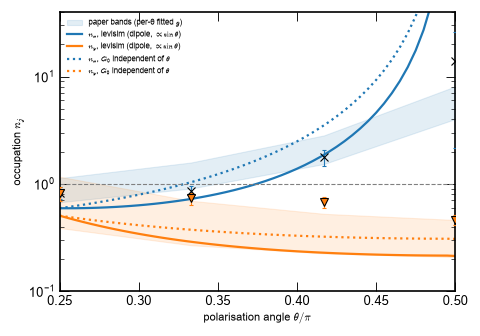

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.2))
tb = f3['theory_bands']
ax.fill_between(tb['θ_over_π'], tb['n_x_lower'], tb['n_x_upper'], color='C0', alpha=0.12, label='paper bands (per-θ fitted $g$)')
ax.fill_between(tb['θ_over_π'], tb['n_y_lower'], tb['n_y_upper'], color='C1', alpha=0.12)
for (name, values), ls in zip(n_θ.items(), ('-', ':')):
    ax.plot(θs/π, values[:, 0], color='C0', ls=ls, lw=2, label=f'$n_x$, {name}')
    ax.plot(θs/π, values[:, 1], color='C1', ls=ls, lw=2, label=f'$n_y$, {name}')
for p in f3['points']:
    for mode, colour, marker in (('x', 'C0', 'x'), ('y', 'C1', 'v')):
        ax.errorbar(p['θ_over_π'], p[f'n_{mode}'], yerr=[[p[f'n_{mode}'] - p[f'n_{mode}_lo']], [p[f'n_{mode}_hi'] - p[f'n_{mode}']]],
                    fmt=marker, color=colour, mec='k', ms=7, capsize=2, zorder=5)
ax.axhline(1, color='grey', ls='--', lw=1)
ax.set_yscale('log')
ax.set_xlim(0.25, 0.5)
ax.set_ylim(0.1, 40)
ax.set_xlabel(r'polarisation angle $\theta/\pi$')
ax.set_ylabel(r'occupation $n_j$')
ax.legend(fontsize=7, frameon=False, loc='upper left')
fig.tight_layout()

## Limits of sideband thermometry (Fig. 4d,e)

The paper's Methods define the test: fix $\Delta/2\pi$ = 240 kHz, set
$\Omega_x = \Delta - \delta$, $\Omega_y = \Delta + \delta$ and $g_x = g_y = g$, take the heating
rates from Eqs. (3) and (4) at each frequency, and compare the true occupation with the one from
sideband thermometry on the heterodyne spectrum: the ratio of the anti-Stokes and Stokes peak
heights of each mode, divided out by the cavity asymmetry
$A_\text{cav} = [\kappa^2 + 4(\Delta+\Omega)^2]/[\kappa^2 + 4(\Delta-\Omega)^2]$, gives
$n = A/(A_\text{cav} - A)$. levisim gives both sides: the true occupation from the Lyapunov
covariance and the heterodyne spectrum from the same drift matrix (here through the vectorised
`paper_tools.heterodyne`, checked against `MultiTrap.heterodyne_spectrum` first). Where the
anti-Stokes or Stokes side no longer shows two peaks, thermometry is impossible (white).

In [ ]:
m_check = fitted_rates_multitrap(232*kHz)
ω_check = np.linspace(-400, 400, 1601) * kHz
m_check.ω_range = ω_check
with quiet():
    S_levisim = m_check.heterodyne_spectrum(LAM)
print(f'paper_tools.heterodyne vs MultiTrap.heterodyne_spectrum: max relative difference '
      f'{np.max(np.abs(heterodyne(m_check, ω_check)/S_levisim - 1)):.1e}')

Δ_MAP = 240*kHz


def heating_rates(Ω_x, Ω_y):
    """Eqs. (3) and (4) at the given frequencies (paper axes): gas + recoil"""
    trap_ = Trap(tweezer=piotrowski_tweezer(), bead=trap.bead, override_Ω_dict={'x': Ω_y, 'y': Ω_x, 'z': Ω_PAPER['z']})
    r = recoil_heating_rates(trap_)
    return (Γ_gas*kB*300/(ħ*Ω_x) + r['y'], Γ_gas*kB*300/(ħ*Ω_y) + r['x'])


def thermometry_error(δ, g, step=0.05*kHz):
    Ω_x, Ω_y = Δ_MAP - δ, Δ_MAP + δ
    Γ_x, Γ_y = heating_rates(Ω_x, Ω_y)
    m = fitted_rates_multitrap(Δ_MAP, g_x=g, g_y=g, Γ_x=Γ_x, Γ_y=Γ_y, Ω_x=Ω_x, Ω_y=Ω_y)
    n_true = n_paper_axes(m)
    w = np.arange(Ω_x - 2*g - 10*kHz, Ω_y + 2*g + 10*kHz, step)
    peaks = {}
    for side, sign in (('AS', +1), ('S', -1)):
        S = heterodyne(m, sign*w) - 1
        idx, _ = find_peaks(S)
        if len(idx) < 2:
            return n_true, None
        idx = np.sort(idx[np.argsort(S[idx])[-2:]])
        refined = []
        for i in idx:
            res = minimize_scalar(lambda ww: -(heterodyne(m, [sign*ww])[0] - 1), method='bounded',
                                  bounds=(w[max(i - 1, 0)], w[min(i + 1, len(w) - 1)]), options=dict(xatol=1e-4*Hz))
            refined.append((res.x, -res.fun))
        peaks[side] = refined
    n_sbt = []
    for j in range(2):
        Ω_peak, S_AS = peaks['AS'][j]
        A = S_AS / peaks['S'][j][1]
        A_cav = (κ_P**2 + 4*(Δ_MAP + Ω_peak)**2) / (κ_P**2 + 4*(Δ_MAP - Ω_peak)**2)
        n_sbt.append(A / (A_cav - A))
    return n_true, np.array(n_sbt)


n_true_fig2, n_sbt_fig2 = thermometry_error(22*kHz, 14.75*kHz)
print(f'at the Fig. 2 parameters (|Ωx-Ωy|/2π = 44 kHz, (gx+gy)/4π = 14.75 kHz): n_true = {np.round(n_true_fig2, 3)},'
      f' n_sideband = {np.round(n_sbt_fig2, 3)}, relative error = {np.round(abs(n_sbt_fig2 - n_true_fig2)/n_true_fig2, 4)}')

splittings = np.linspace(1, 55, 22) * kHz          # |Ωx - Ωy|
couplings = np.linspace(2.5, 25, 16) * kHz         # (gx + gy)/2 = g
error = np.full((2, len(couplings), len(splittings)), np.nan)
t0 = time.time()
for a, g in enumerate(couplings):
    for b, split in enumerate(splittings):
        n_true, n_sbt = thermometry_error(split/2, g)
        if n_sbt is not None and np.all(n_sbt > 0):
            error[:, a, b] = abs(n_sbt - n_true) / n_true
print(f'map of {error[0].size} points in {time.time() - t0:.0f} s; thermometry impossible at {np.isnan(error[0]).sum()} points')

paper_tools.heterodyne vs MultiTrap.heterodyne_spectrum: max relative difference 3.3e-16
at the Fig. 2 parameters (|Ωx-Ωy|/2π = 44 kHz, (gx+gy)/4π = 14.75 kHz): n_true = [0.543 0.763], n_sideband = [0.537 0.756], relative error = [0.0122 0.0103]
map of 352 points in 5 s; thermometry impossible at 13 points


Out[8]: <matplotlib.colorbar.Colorbar at 0x1683eee10>


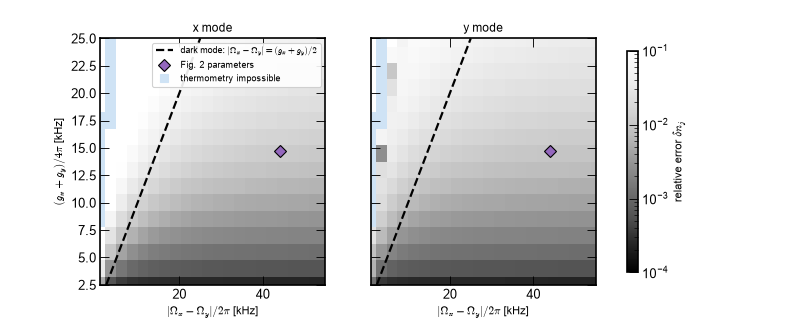

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
norm = LogNorm(1e-4, 1e-1)
cmap = plt.get_cmap('Greys_r').copy()
cmap.set_bad('#cfe3f5')   # thermometry impossible (fewer than two peaks per sideband)
for ax, err, mode in zip(axes, error, 'xy'):
    mesh = ax.pcolormesh(splittings/kHz, couplings/kHz, np.clip(err, 1e-4, 1e-1), cmap=cmap, norm=norm, shading='nearest')
    ax.plot(couplings/kHz, couplings/kHz, 'k--', lw=2, label=r'dark mode: $|\Omega_x - \Omega_y| = (g_x + g_y)/2$')
    ax.plot(44, 14.75, 'D', color='C4', mec='k', ms=8, label='Fig. 2 parameters')
    ax.plot([], [], 's', color='#cfe3f5', ms=8, label='thermometry impossible')
    ax.set_xlim(splittings[0]/kHz, splittings[-1]/kHz)
    ax.set_ylim(couplings[0]/kHz, couplings[-1]/kHz)
    ax.set_xlabel(r'$|\Omega_x - \Omega_y|/2\pi$ [kHz]')
    ax.set_title(f'{mode} mode', fontsize=11)
axes[0].set_ylabel(r'$(g_x + g_y)/4\pi$ [kHz]')
axes[0].legend(fontsize=8, loc='upper right', framealpha=0.9)
fig.colorbar(mesh, ax=axes, label=r'relative error $\delta n_j$', shrink=0.9)

## Summary

All numbers below are printed by the cells above.

**Agreement.**

- **Rates.** The paraxial frequencies from the stated power and waists match the measured $x$ and
  $y$ frequencies (223.7 and 267.4 kHz against 224 and 268 kHz). levisim's recoil heating
  reproduces the Methods values (0.820 and 1.371 kHz against 0.825 and 1.379 kHz), and its
  Epstein gas damping matches the Methods' $\gamma$ to 1 %.
- **Detuning (Fig. 2b).** With the fitted couplings and heating rates, levisim's full $x$-$y$-cavity
  model reproduces the paper's simulation. The lower edges of the uncertainty band (the
  $g + \sigma$, $\Gamma - \sigma$ corner) match the paper's $n_x$ band within 0.01 at all five
  detunings (0.33 against 0.34 at 232.5 kHz, identical to two decimals at the other four), and lie
  6-9 % below its $n_y$ band. The paper's upper edges are
  narrower than the full corner range; its band construction is not specified.
- **Thermometry error (Fig. 4d,e).** Peak-height thermometry on levisim's heterodyne spectrum,
  compared with levisim's exact occupations, reproduces the structure of the paper's map:
  negligible error for well-separated modes and weak coupling, growing towards the dark-mode
  line, and impossible where the peaks merge. At the Fig. 2 parameters the error is 1.2 % ($x$) and
  1.0 % ($y$), the paper's "about 1 %".

**Discrepancies, and where they come from.**

- **Coupling magnitude.** The coupling from Eq. (1) with the stated parameters - identical to
  levisim's coupling, checked term by term - is 2.47× ($x$) and 2.07× ($y$) the fitted value. The
  paper uses the fitted values and does not compare them with Eq. (1). With first-principles
  couplings levisim predicts $n_x = 0.22$, $n_y = 0.28$ at 232.5 kHz, well below the measured
  0.83 and 0.81. The stated parameter set therefore over-predicts the scattering into the cavity
  mode. The reason is not identifiable from the paper (power at the focus, focus-mode overlap and
  particle size enter as $\sqrt{P}$, linearly and as $R^{3}$).
- **Data above both theories.** Even with the fitted rates, the central levisim curve lies below the
  measured points at every detuning (232.5 kHz: 0.60 and 0.53 against 0.83 and 0.81). The points
  for $n_y$ at 362-662 kHz, and for $n_x$ at 662 kHz, lie above the upper edge of both levisim's band
  and the paper's. levisim and the paper's model agree with each other here; it is the data that
  sit high.
- **Methods typos.** The Methods' gas heating rates are half of their own Eq. (3) with their own
  $\gamma$, which is irrelevant because recoil dominates. Their $G_0 \propto \cos\theta$ carries over
  the angle convention of Gonzalez-Ballestero et al. (2019). Taken literally with this paper's
  $\theta$, it would make $g_y \propto \sin\theta\cos\theta$ vanish at $\theta = \pi/2$, contradicting
  the measured $n_y = 0.46$ there.
- **Polarisation angle (Fig. 3e).** At $\theta = 0.417\pi$ levisim's dipole law gives
  $n_x = 1.79$ against the measured $1.77 \pm 0.31$, whereas a $\theta$-independent $G_0$ gives 3.4.
  The $n_x$ trend therefore favours levisim's $\sin\theta$ factor. For $n_y$ both laws stay below
  the data by about the factor already present at $0.25\pi$, so $n_y$ does not discriminate. At
  $\theta = \pi/2$ the model's $g_x$ vanishes and $n_x$ grows to the recoil-heated steady state; the
  measured $14 \pm 12$ reflects the polarisation imperfections the paper describes.

**Not modelled.** Laser phase noise (suppressed in the experiment), the $z$ mode (uncoupled at the
node), and polarisation imperfections. Recoil heating is added outside levisim with
`paper_tools.add_heating`.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 7.8 s
